# Innovación: prior incierto y costo de esperar

## Resumen
En el caso sintético, una regla común conservadora mejora el peor valor de 86,72 a120,45 unidades sin demora. Con descuento diario0,2, el baseline nominal pierde363,95 bajo el prior pesimista; el gate robusto elige no estudiar y obtiene0. No se afirma dominancia universal.

## Contexto y método
Una política terminal se fija **antes** de observar el prior verdadero. Para cada K, escala solo si todos los priors del conjunto dan utilidad posterior positiva. Cada prior evalúa esa misma regla: no se escoge una política oráculo por escenario. El estudio de n observaciones demora n/q días, y el payoff futuro se multiplica por exp(-r n/q); el costo del piloto se paga hoy.

Se maximiza el peor valor sobre un conjunto finito de priors, tamaños y una familia restringida de reglas. No es una solución minimax sobre todas las políticas. No hay actualización de pesos de modelos ni robustez frente a distribuciones fuera del conjunto.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
cfg=json.loads(Path('robust-config.json').read_text())
display(cfg)

{'seed': 20261024,
 'case': {'alpha': 6,
  'beta': 4,
  'population': 10000,
  'benefit': 10,
  'unit_cost': 6,
  'fixed_rollout': 0,
  'experiment_fixed': 100,
  'experiment_unit': 5},
 'priors': [[6, 4], [4, 6], [8, 2]],
 'sizes': [0, 10, 25, 50, 100, 200, 500],
 'discounts': [0, 0.01, 0.05, 0.2, 1],
 'observations_per_day': 10,
 'replicates': 200000,
 'units': 'synthetic monetary units; rate per day and study speed observations/day',
 'hypothesis': 'worst-prior value of common robust policy >=0 because stopping is feasible; compare nominal common policy on same priors'}

## Resultados
Unidad monetaria sintética común. Priors6/4,4/6,8/2; misma población futura10000, beneficio10 y costo6. Tasa de descuento de escenario; no estimación financiera real.

,daily_discount,policy,n,worst_value,objective,prior_0_value,prior_1_value,prior_2_value
0,0.00,nominal,50,86.717,5140.418,5140.418,86.717,19935.401
1,0.00,robust,50,120.453,120.453,4909.624,120.453,19679.921
2,0.01,nominal,50,65.418,4872.648,4872.648,65.418,18946.070
3,0.01,robust,50,97.508,97.508,4653.109,97.508,18703.050
4,0.05,nominal,25,-31.944,4251.291,4251.291,-31.944,17409.225
5,0.05,robust,25,61.312,61.312,3618.332,61.312,16456.711
6,0.20,nominal,10,-363.949,3289.488,3289.488,-363.949,15337.446
7,0.20,robust,0,0.000,0.000,0.000,0.000,0.000
8,1.00,nominal,10,-246.133,1395.462,1395.462,-246.133,6808.958
9,1.00,robust,0,0.000,0.000,0.000,0.000,0.000


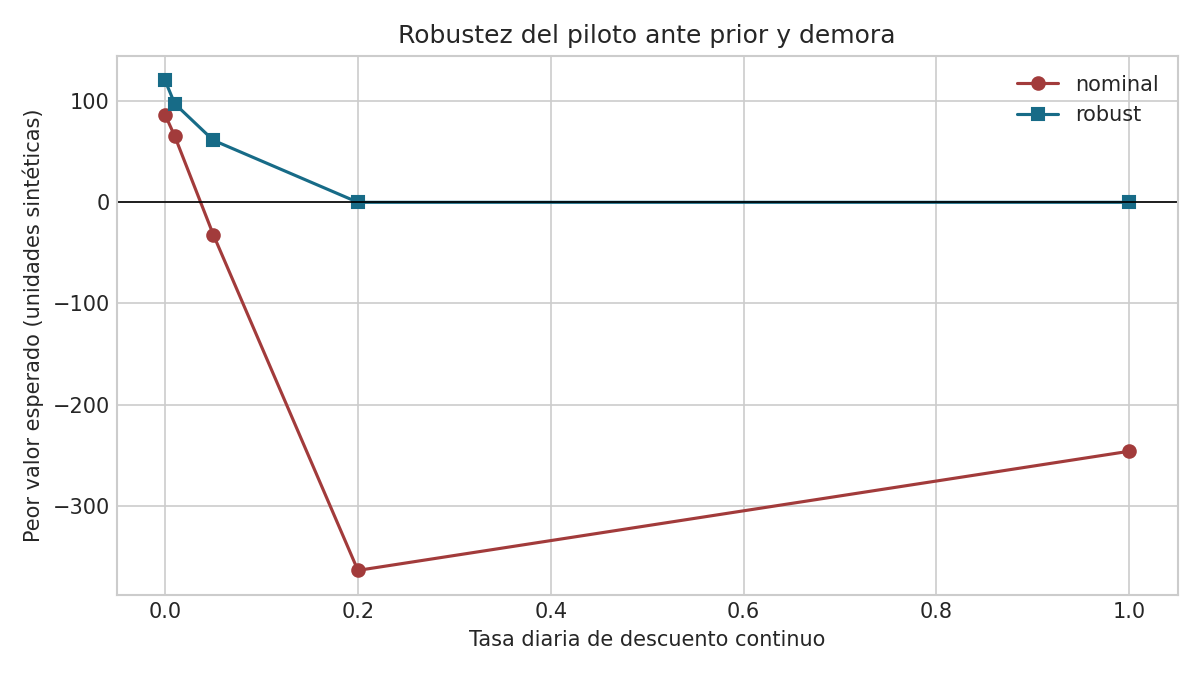

In [2]:
table=pd.read_csv('results/robust-designs.csv')
display(table.round(3))
display(Image(filename='results/robust-decision.png'))

## Validación y ablation
Prior único y demora cero recupera el motor23. MC genera p y K; la acción depende solo de K y priors fijados. El p latente solo evalúa payoff. La opción n0 evita pagar evidencia inútil bajo las condiciones de este caso, pues todos pueden detener sin costo.

In [3]:
summary=json.loads(Path('results/robust-summary.json').read_text())
display(summary)
for check in summary['mc_checks']:
    assert abs(check['mc_mean']-check['exact']) < 5*check['mc_se']
assert table.loc[table.policy.eq('robust'),'worst_value'].min()>=-1e-8

{'selected_robust': {'n': 50,
  'objective': 120.45257966819702,
  'scenario_values': [4909.623761217213, 120.45257966819702, 19679.9210803936],
  'worst_value': 120.45257966819702},
 'mc_checks': [{'prior': [6, 4],
   'exact': 4909.623761217213,
   'mc_mean': 4875.670355302008,
   'mc_se': 18.565476140716562},
  {'prior': [4, 6],
   'exact': 120.45257966819702,
   'mc_mean': 122.96698371966329,
   'mc_se': 5.944914594205227},
  {'prior': [8, 2],
   'exact': 19679.9210803936,
   'mc_mean': 19646.33398901625,
   'mc_se': 25.799498312098702}],
 'runtime_seconds': 0.21346680200002766,
 'seed': 20261024,
 'replicates_per_prior': 200000}

## Decisión y límites
Continuar con piloto cuando crea valor bajo el conjunto; detener si demora/costo elimina valor. Ajustar si prior no es defendible, metricas no son causales, ritmo del piloto cambia o hay costos omitidos. Robustez sacrifica valor nominal: con r0 baja5140,42 a4909,62. No prueba eficacia IA. Ver informe-2026-10-24.md y referencias.bib.